# Phase 9 — Model Comparison

**Advanced Equity Portfolio Risk Management Platform**
**QFI Internship — Team 2 (Market Risk)** · *Submitted by: Atharv Pratap Singh Chauhan*

---

## Objective

Phases 4–7 produced four one-day-ahead VaR families — unscaled **Historical Simulation (HS)**, **EWMA-scaled**, **GARCH(1,1)-scaled** and **GJR-GARCH-scaled** HS — and Phase 8 backtested each against Kupiec, Christoffersen and Basel. A risk desk still has to pick *one* model to run. Phase 9 scores all four on the three axes that decide that choice and produces a transparent ranking.

| Axis | Question | Metric |
|---|---|---|
| **Calibration** | Do breaches arrive at the right rate, un-clustered? | Christoffersen CC p-value, \|rate − target\| |
| **Capital efficiency** | How much capital does the VaR tie up? | mean VaR as % of NAV |
| **Sharpness / scoring** | Is the whole quantile forecast good, not just the hit rate? | pinball (quantile) loss, Lopez magnitude loss |

A model that is accurate *and* ties up less capital *and* scores well on a proper loss function is the one to deploy. We rank at the regulatory headline (**99%, 250-day**) and report stability across all nine window×confidence cells.

## 1. What makes one VaR model better than another

**Calibration is necessary but not sufficient.** Two models can both pass Kupiec (right *average* breach rate) yet differ sharply: one may be needlessly conservative (large VaR, capital wasted) and the other may cluster its breaches (Christoffersen rejects it). We therefore keep the Phase 8 coverage verdicts as the primary gate and add efficiency and scoring as tie-breakers.

**Capital efficiency.** Among models that are *correctly* calibrated, the one with the lower average VaR frees regulatory capital without raising breach risk. A low VaR on its own is not a virtue — it is only a virtue once coverage is passed.

**Proper scoring rules** judge the whole forecast, not just the 0/1 hit:

- **Pinball (quantile) loss** at level $\tau=1-c$ for realised return $r_t$ and VaR-quantile forecast $q_t=-\text{VaR}_t/\text{NAV}_t$:
$$\text{PB}_t=\begin{cases}\tau\,(r_t-q_t) & r_t\ge q_t\\(\tau-1)(r_t-q_t) & r_t<q_t\end{cases}$$
It is minimised in expectation by the *true* conditional quantile, so it rewards a VaR that is both correctly centred and as tight as the data allow. Lower is better.

- **Lopez magnitude loss** penalises not just whether a breach happened but *how far* realised loss overshot VaR: $\;L_t = 1 + (\,\text{loss}_t-\text{VaR}_t)^2$ on breach days (here measured in return space), $0$ otherwise. A model that breaches rarely *and* mildly scores best.

**Ranking.** At the headline cell we rank the four models on four criteria — CC p-value (↑), coverage error $|\hat\pi-p|$ (↓), mean VaR %NAV (↓) and pinball loss (↓) — and average the ranks. Equal weights; calibration enters twice (CC p-value and coverage error) because regulatory acceptance dominates the decision.

In [1]:
from __future__ import annotations
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

PALETTE = {"ink":"#1B2A41","muted":"#8C99A6","profit":"#2E7D68","loss":"#B03A2E",
           "HS":"#E08A2E","EWMA":"#6A2C91","GARCH":"#1F6F8B","GJR":"#9B2242",
           "green":"#2E7D68","amber":"#E0A52E","red":"#B03A2E","light":"#E9EDF2"}
sns.set_theme(style="whitegrid", context="talk")
mpl.rcParams.update({"figure.dpi":110,"savefig.dpi":200,"savefig.bbox":"tight",
    "figure.facecolor":"white","axes.facecolor":"white","axes.edgecolor":PALETTE["muted"],
    "axes.titlecolor":PALETTE["ink"],"axes.titleweight":"bold","axes.titlesize":14,
    "axes.labelsize":11,"axes.titlepad":12,"grid.color":"#E3E7EB","grid.linewidth":0.8,
    "xtick.labelsize":9,"ytick.labelsize":9,"legend.fontsize":9,"font.family":"DejaVu Sans"})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 180)

WINDOWS=(250,500,750); CONFIDENCES=(0.95,0.99,0.995)
HEADLINE_W=250; HEADLINE_C=0.99; CURRENCY="₹"
OUT=Path("outputs"); OUT.mkdir(parents=True, exist_ok=True); (OUT/"charts").mkdir(exist_ok=True)
def cl_tag(c): return f"{100*c:g}".replace(".","p")
def pct(x,dp=2): return "n/a" if not np.isfinite(x) else f"{100*x:.{dp}f}%"
print("Phase 9 comparison config ready.")


Phase 9 comparison config ready.


## 2. Load the four model exports and the Phase 8 backtest

Each scaled-VaR export carries realised P&L, start-of-day NAV, the embedded unscaled HS benchmark and the model's own scaled VaR. We reuse Phase 8's `Backtest_Results.csv` for the coverage diagnostics (so the two phases agree by construction) and compute the efficiency and scoring metrics here from the raw forecasts.

In [2]:
def locate(name):
    for p in [Path(name), OUT/name, Path("..")/name, Path("..")/"outputs"/name]:
        if p.exists(): return p
    return None

SOURCES = [("Historical Simulation","HS",None),
           ("EWMA-scaled HS","EWMA","EWMA_Scaled_VaR.csv"),
           ("GARCH-scaled HS","GARCH","GARCH_Scaled_VaR.csv"),
           ("GJR-GARCH-scaled HS","GJR","GJR_GARCH_Scaled_VaR.csv")]
frames = {}
for _, prefix, fname in SOURCES:
    if fname is None: continue
    p = locate(fname)
    if p is not None:
        frames[prefix] = pd.read_csv(p, index_col=0, parse_dates=True)
        print(f"Loaded {prefix:<6} <- {p}")
assert frames, "No scaled-VaR exports found; run Phases 5–7 first."

any_df = next(iter(frames.values()))
pnl = any_df["Portfolio_PnL"].astype(float)
nav = any_df["Start_of_Day_Value"].astype(float)
MODELS = [(lab, pre) for (lab, pre, _) in SOURCES if pre == "HS" or pre in frames]

def var_series(prefix, w, c):
    tag = cl_tag(c); col = f"{prefix}_VaR_{w}d_{tag}"
    df = any_df if prefix == "HS" else frames[prefix]
    return df[col].astype(float) if col in df else None

bt = pd.read_csv(locate("Backtest_Results.csv"))
print(f"\nBacktest diagnostics: {bt.shape[0]} rows from Phase 8")
print(f"Models under comparison: {[m[0] for m in MODELS]}")


Loaded EWMA   <- outputs/EWMA_Scaled_VaR.csv
Loaded GARCH  <- outputs/GARCH_Scaled_VaR.csv
Loaded GJR    <- outputs/GJR_GARCH_Scaled_VaR.csv

Backtest diagnostics: 36 rows from Phase 8
Models under comparison: ['Historical Simulation', 'EWMA-scaled HS', 'GARCH-scaled HS', 'GJR-GARCH-scaled HS']


## 3. Comparison metrics

For every model/window/confidence we compute the capital-efficiency and scoring metrics below, then merge the Phase 8 coverage columns onto them. All scoring is done in **return space** (P&L ÷ NAV) so magnitudes are unit-free and comparable across the sample.

In [3]:
def efficiency_metrics(prefix, w, c):
    v = var_series(prefix, w, c)
    if v is None: return None
    m = v.notna()
    v = v[m]; r = (pnl[m]/nav[m]); q = -(v/nav[m])      # VaR quantile in return space (negative)
    tau = 1-c
    breach = r < q
    pinball = np.where(r >= q, tau*(r-q), (tau-1)*(r-q)).mean()   # proper quantile loss
    exceed = (q - r)[breach]                                      # how far past VaR, return space
    lopez = (1 + (exceed*100)**2).sum()/len(r)                    # Lopez magnitude loss (0 if no breach)
    return {"MeanVaR_pctNAV":(v/nav[m]).mean()*100,
            "VaR_responsiveness_pct":v.pct_change().abs().mean()*100,
            "Pinball_bps":pinball*1e4,
            "Lopez":lopez,
            "MeanBreach_bps":(exceed.mean()*1e4 if breach.any() else 0.0)}

rows = []
for label, prefix in MODELS:
    for w in WINDOWS:
        for c in CONFIDENCES:
            eff = efficiency_metrics(prefix, w, c)
            if eff is None: continue
            cov = bt[(bt.Prefix==prefix)&(bt.Window==w)&(bt.Confidence==c)]
            cov = cov.iloc[0] if len(cov) else {}
            rows.append({"Model":label,"Prefix":prefix,"Window":w,"Confidence":c,
                "Exceptions":cov.get("Exceptions",np.nan),"Rate":cov.get("Rate",np.nan),
                "CovErr":abs(cov.get("Rate",np.nan)-(1-c)),
                "Kupiec_p":cov.get("Kupiec_p",np.nan),"CC_p":cov.get("CC_p",np.nan),
                "Basel":cov.get("Basel","-"), **eff})
comp = pd.DataFrame(rows)
comp.to_csv(OUT/"Model_Comparison.csv", index=False)
print(f"Computed {len(comp)} comparison rows -> outputs/Model_Comparison.csv")

# self-check: pinball loss is minimised by a well-calibrated model over a reckless one
_h = comp[(comp.Window==HEADLINE_W)&(comp.Confidence==HEADLINE_C)].set_index("Prefix")
assert _h.loc["GJR","Pinball_bps"] <= _h.loc["HS","Pinball_bps"], "scaled model should not score worse than unscaled HS"
print("Metrics self-check passed.")


Computed 36 comparison rows -> outputs/Model_Comparison.csv
Metrics self-check passed.


## 4. Headline comparison table (99%, 250-day)

Coverage columns come from Phase 8; efficiency and scoring columns are computed here. `MeanVaR_pctNAV` is capital tied up (lower is cheaper, *given* calibration passes); `Pinball_bps` and `Lopez` are proper scores where **lower is better**.

In [4]:
h = comp[(comp.Window==HEADLINE_W)&(comp.Confidence==HEADLINE_C)].copy()
h = h.set_index("Model").reindex([m[0] for m in MODELS])
view = h[["Exceptions","Rate","CC_p","Basel","MeanVaR_pctNAV","VaR_responsiveness_pct",
          "Pinball_bps","Lopez","MeanBreach_bps"]]
sty = (view.style
    .format({"Rate":"{:.2%}","CC_p":"{:.3f}","MeanVaR_pctNAV":"{:.2f}%",
             "VaR_responsiveness_pct":"{:.2f}%","Pinball_bps":"{:.2f}","Lopez":"{:.3f}",
             "MeanBreach_bps":"{:.1f}"})
    .highlight_min(subset=["MeanVaR_pctNAV","Pinball_bps","Lopez"], color="#DDF0E8")
    .highlight_max(subset=["CC_p"], color="#DDF0E8"))
display(sty)


,Exceptions,Rate,CC_p,Basel,MeanVaR_pctNAV,VaR_responsiveness_pct,Pinball_bps,Lopez,MeanBreach_bps
Model,,,,,,,,,
Historical Simulation,22,1.75%,0.037,GREEN,3.50%,1.15%,5.00,0.033,82.0
EWMA-scaled HS,18,1.43%,0.184,GREEN,3.45%,3.57%,4.43,0.024,63.5
GARCH-scaled HS,18,1.43%,0.269,GREEN,3.35%,3.36%,4.34,0.023,64.4
GJR-GARCH-scaled HS,17,1.35%,0.388,GREEN,3.32%,2.82%,4.31,0.024,68.5


### Chart 1 — Calibration vs capital efficiency

The decision plane. **Up** = better calibrated (higher Christoffersen CC p-value, above the 0.05 line is a regulatory pass); **left** = cheaper capital (lower mean VaR). The best model sits in the upper-left: accurate *and* efficient.

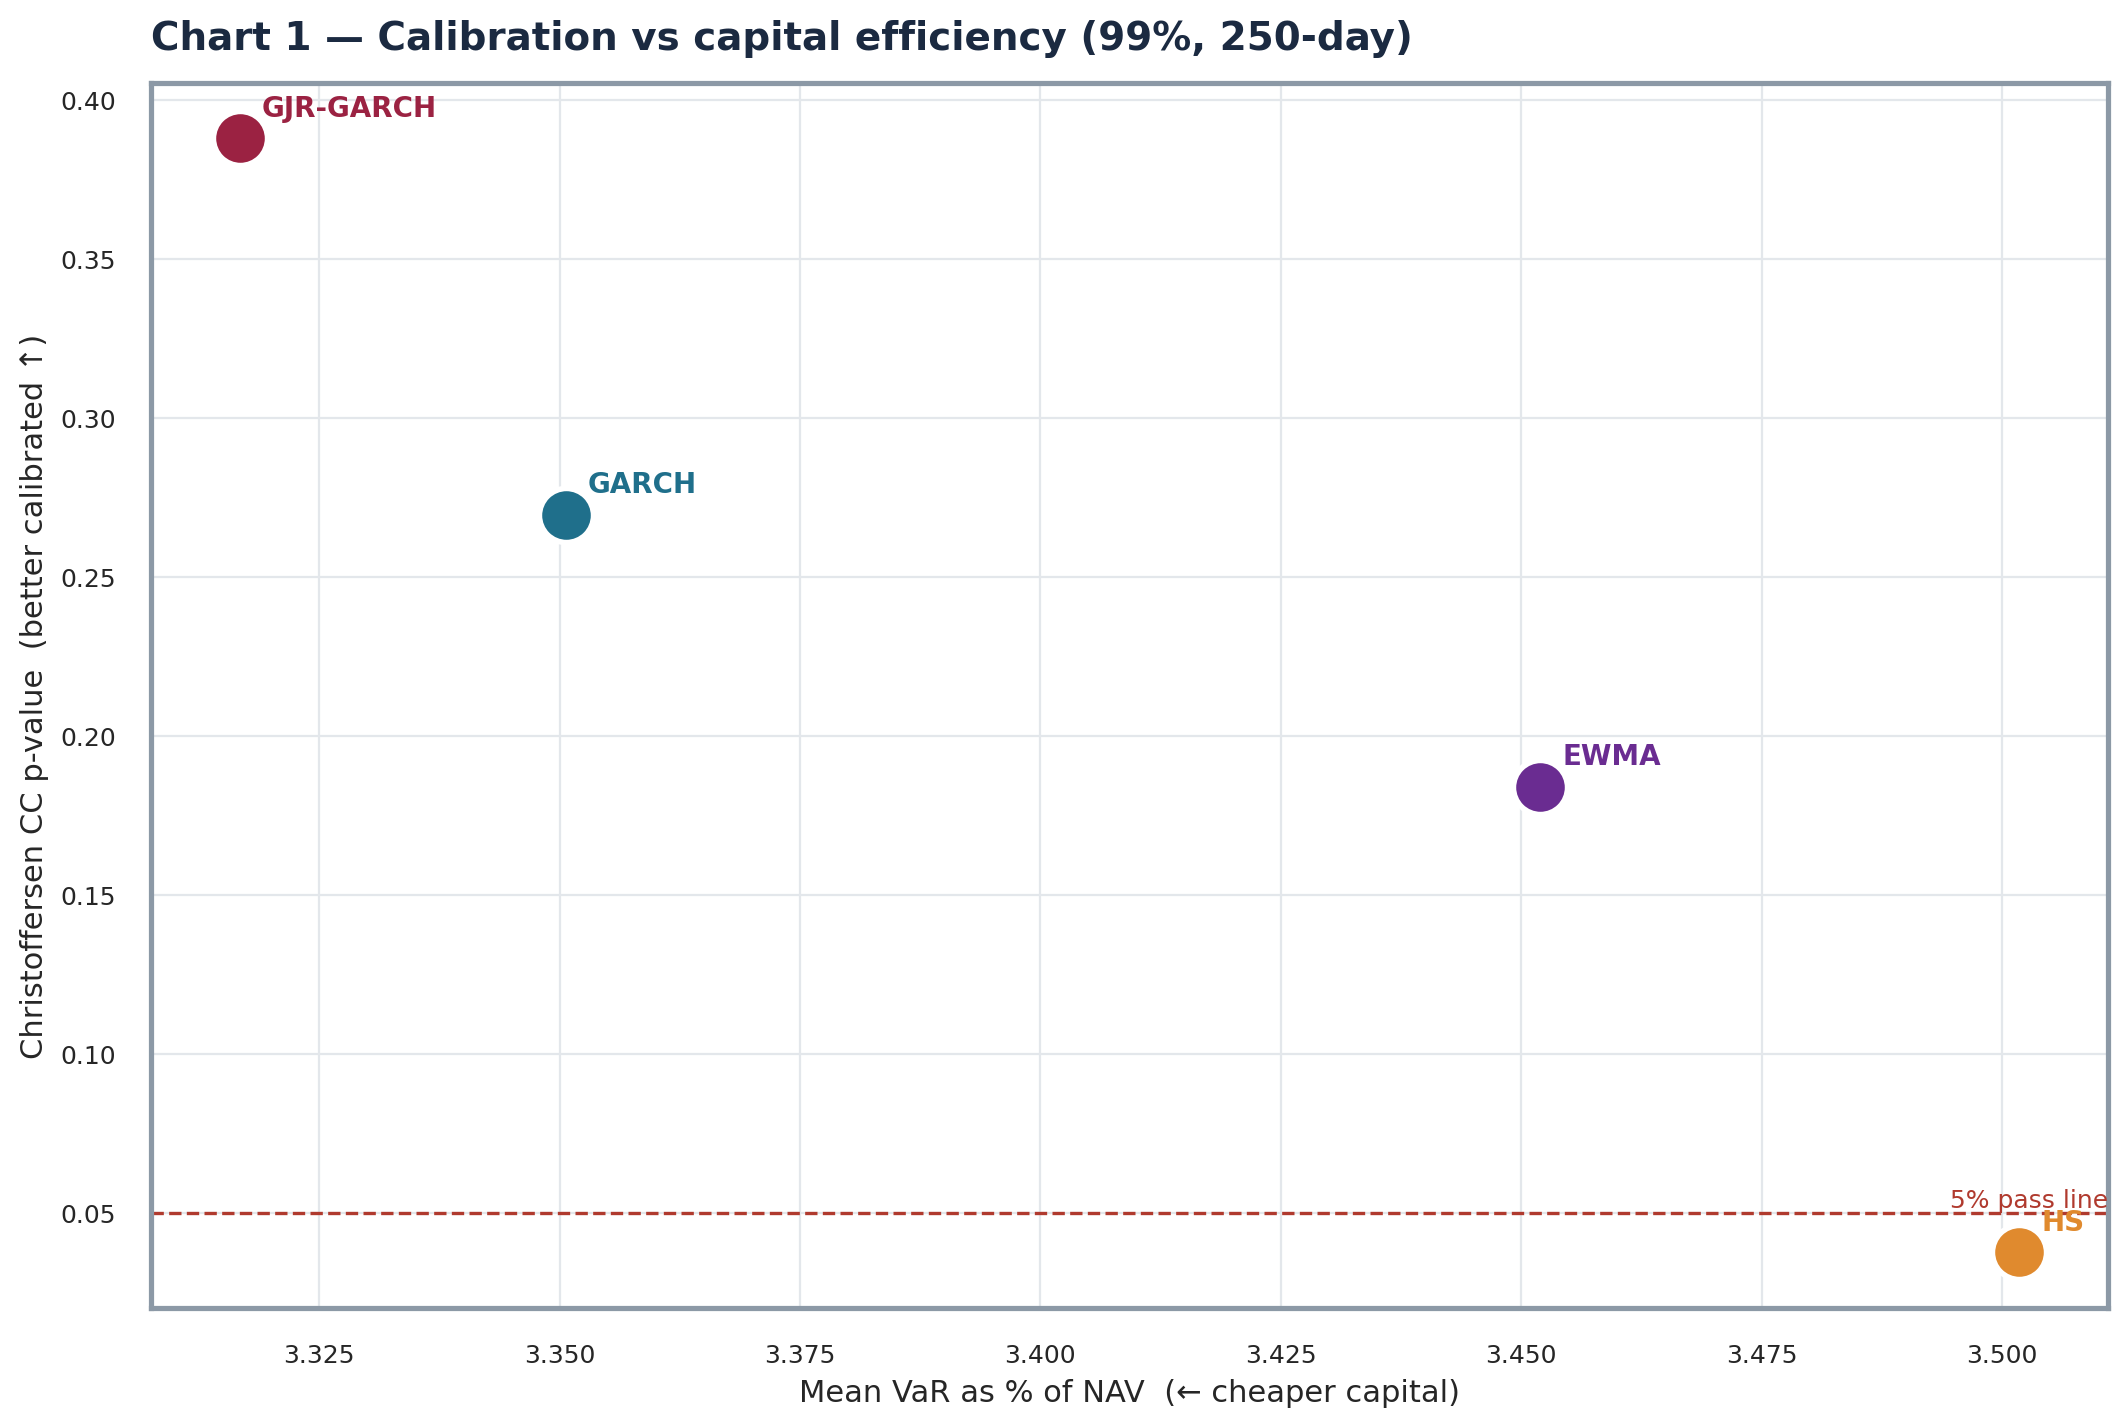

In [5]:
fig, ax = plt.subplots(figsize=(11, 7.5))
for label, prefix in MODELS:
    row = h.loc[label]
    ax.scatter(row["MeanVaR_pctNAV"], row["CC_p"], s=380, color=PALETTE[prefix],
               edgecolor="white", linewidth=2, zorder=5)
    ax.annotate(label.replace("-scaled HS","").replace("Historical Simulation","HS"),
                (row["MeanVaR_pctNAV"], row["CC_p"]), xytext=(8,8),
                textcoords="offset points", fontsize=10, fontweight="bold", color=PALETTE[prefix])
ax.axhline(0.05, color=PALETTE["red"], ls="--", lw=1.2)
ax.text(ax.get_xlim()[1], 0.05, " 5% pass line", color=PALETTE["red"], va="bottom", ha="right", fontsize=9)
ax.set_xlabel("Mean VaR as % of NAV  (← cheaper capital)")
ax.set_ylabel("Christoffersen CC p-value  (better calibrated ↑)")
ax.set_title("Chart 1 — Calibration vs capital efficiency (99%, 250-day)", loc="left")
fig.tight_layout(); fig.savefig(OUT/"charts/09_calibration_vs_efficiency.png", facecolor="white"); plt.show()


### Chart 2 — VaR paths side by side (99%, 250-day)

How differently the four models breathe. Unscaled HS steps slowly (window roll-off); the vol-scaled models react to volatility clusters within days. Realised loss is shaded behind.

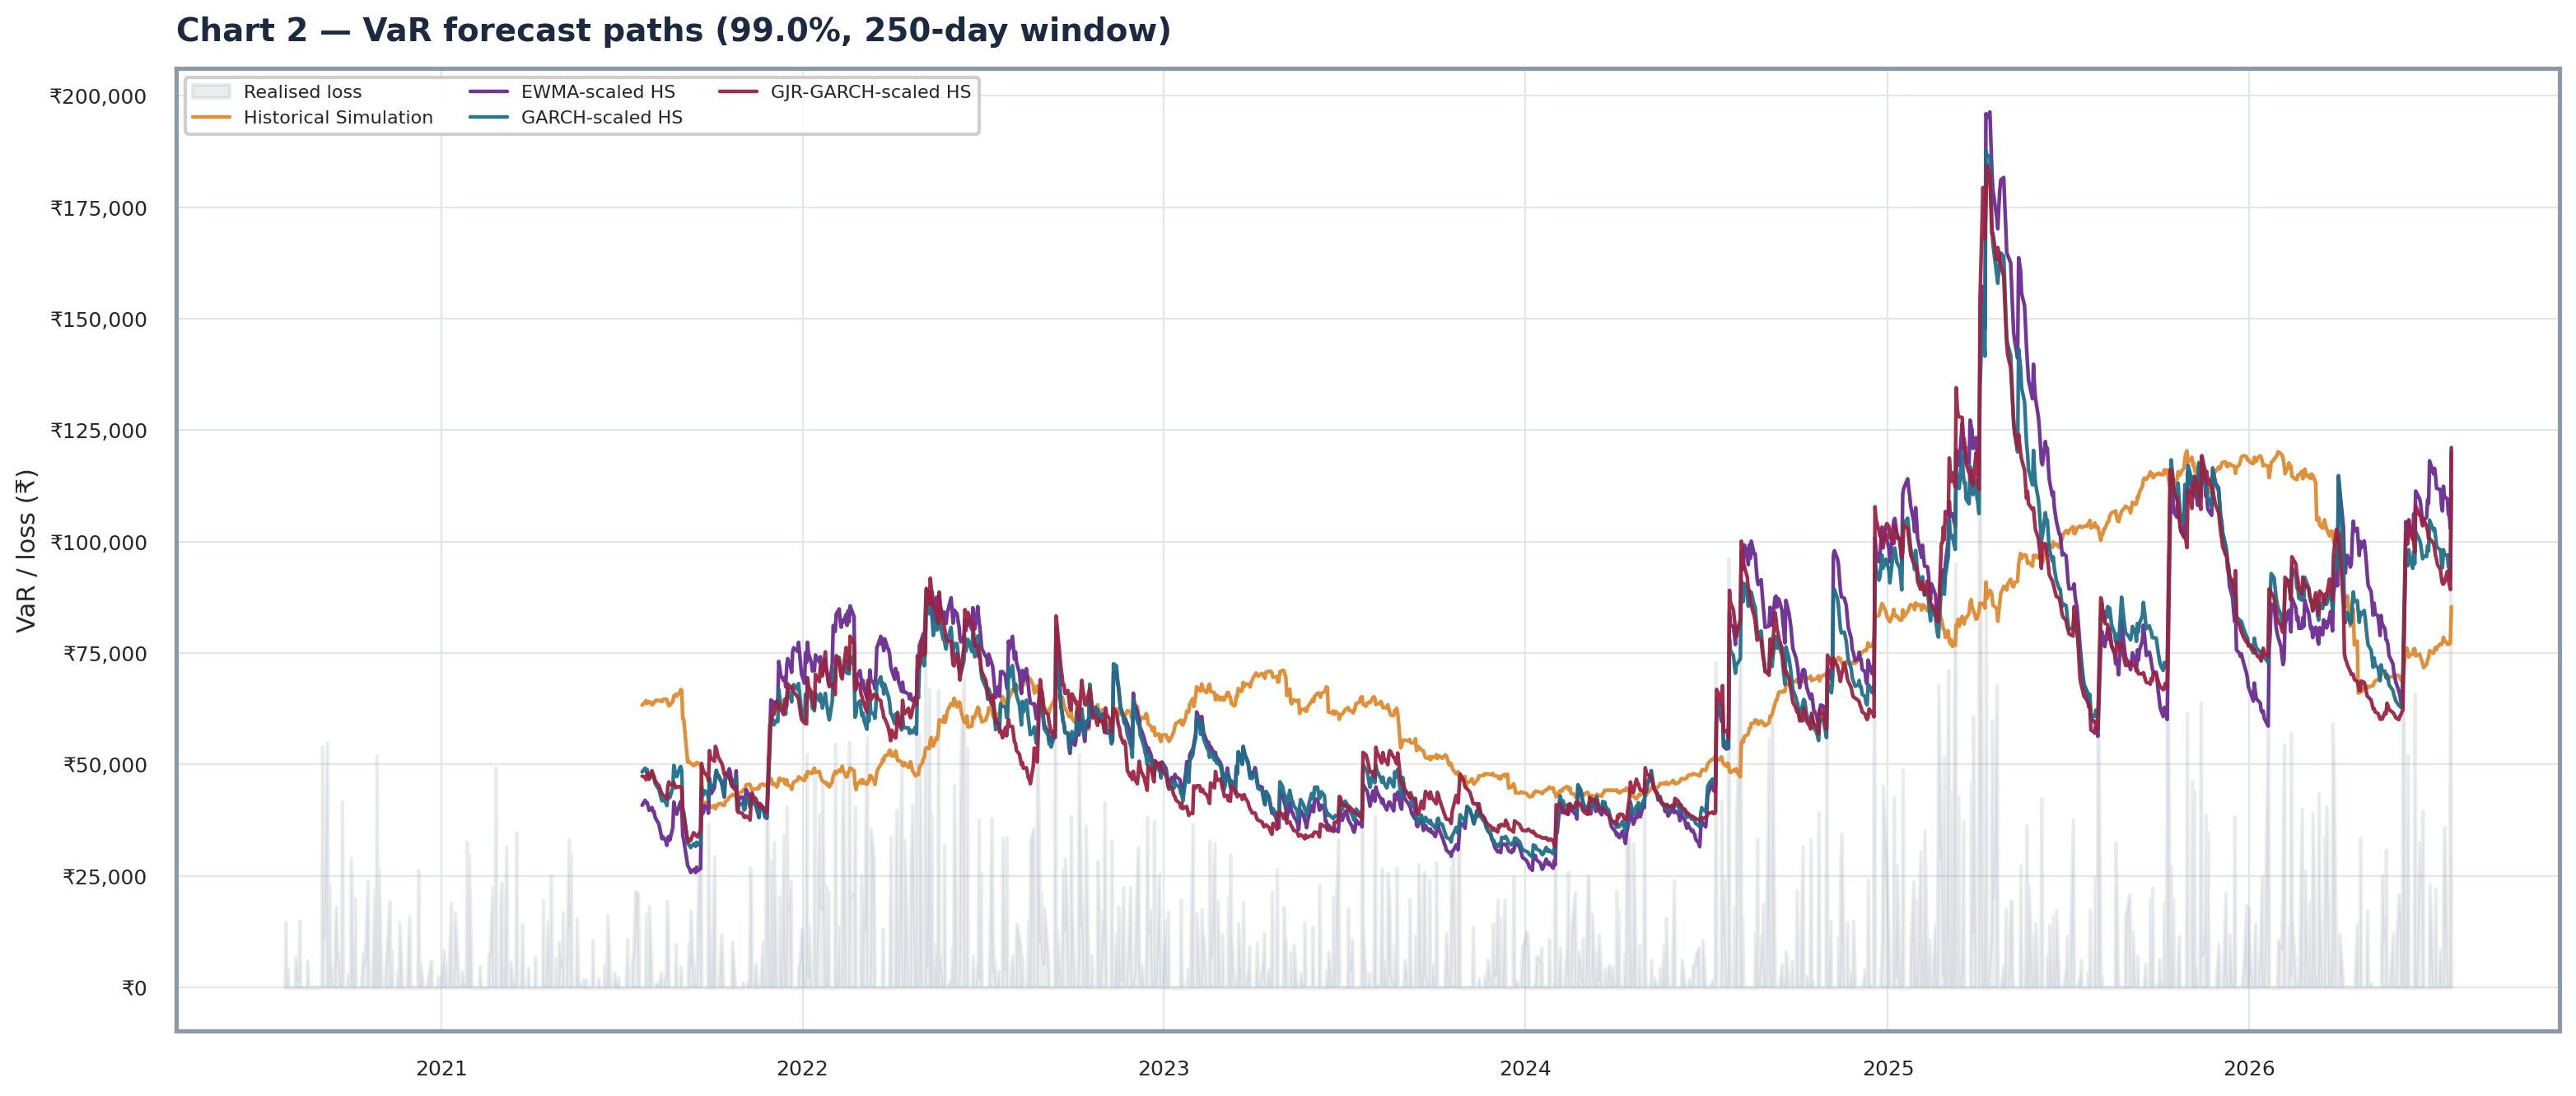

In [6]:
w, c = HEADLINE_W, HEADLINE_C
loss = -pnl
fig, ax = plt.subplots(figsize=(16, 7))
ax.fill_between(loss.index, 0, loss.clip(lower=0), color=PALETTE["muted"], alpha=.18, label="Realised loss")
for label, prefix in MODELS:
    v = var_series(prefix, w, c)
    if v is None: continue
    ax.plot(v.index, v, color=PALETTE[prefix], lw=1.6, alpha=.95, label=label)
ax.set_title(f"Chart 2 — VaR forecast paths ({c:.1%}, {w}-day window)", loc="left")
ax.set_ylabel(f"VaR / loss ({CURRENCY})")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter(CURRENCY+"{x:,.0f}"))
ax.legend(ncol=3, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(OUT/"charts/09_var_paths.png", facecolor="white"); plt.show()


### Chart 3 — Proper-scoring losses across windows

Pinball (quantile) loss at the headline confidence, by model and window. Lower bars are better-calibrated-and-sharper forecasts. Consistency across windows signals a robust model, not one tuned to a single lookback.

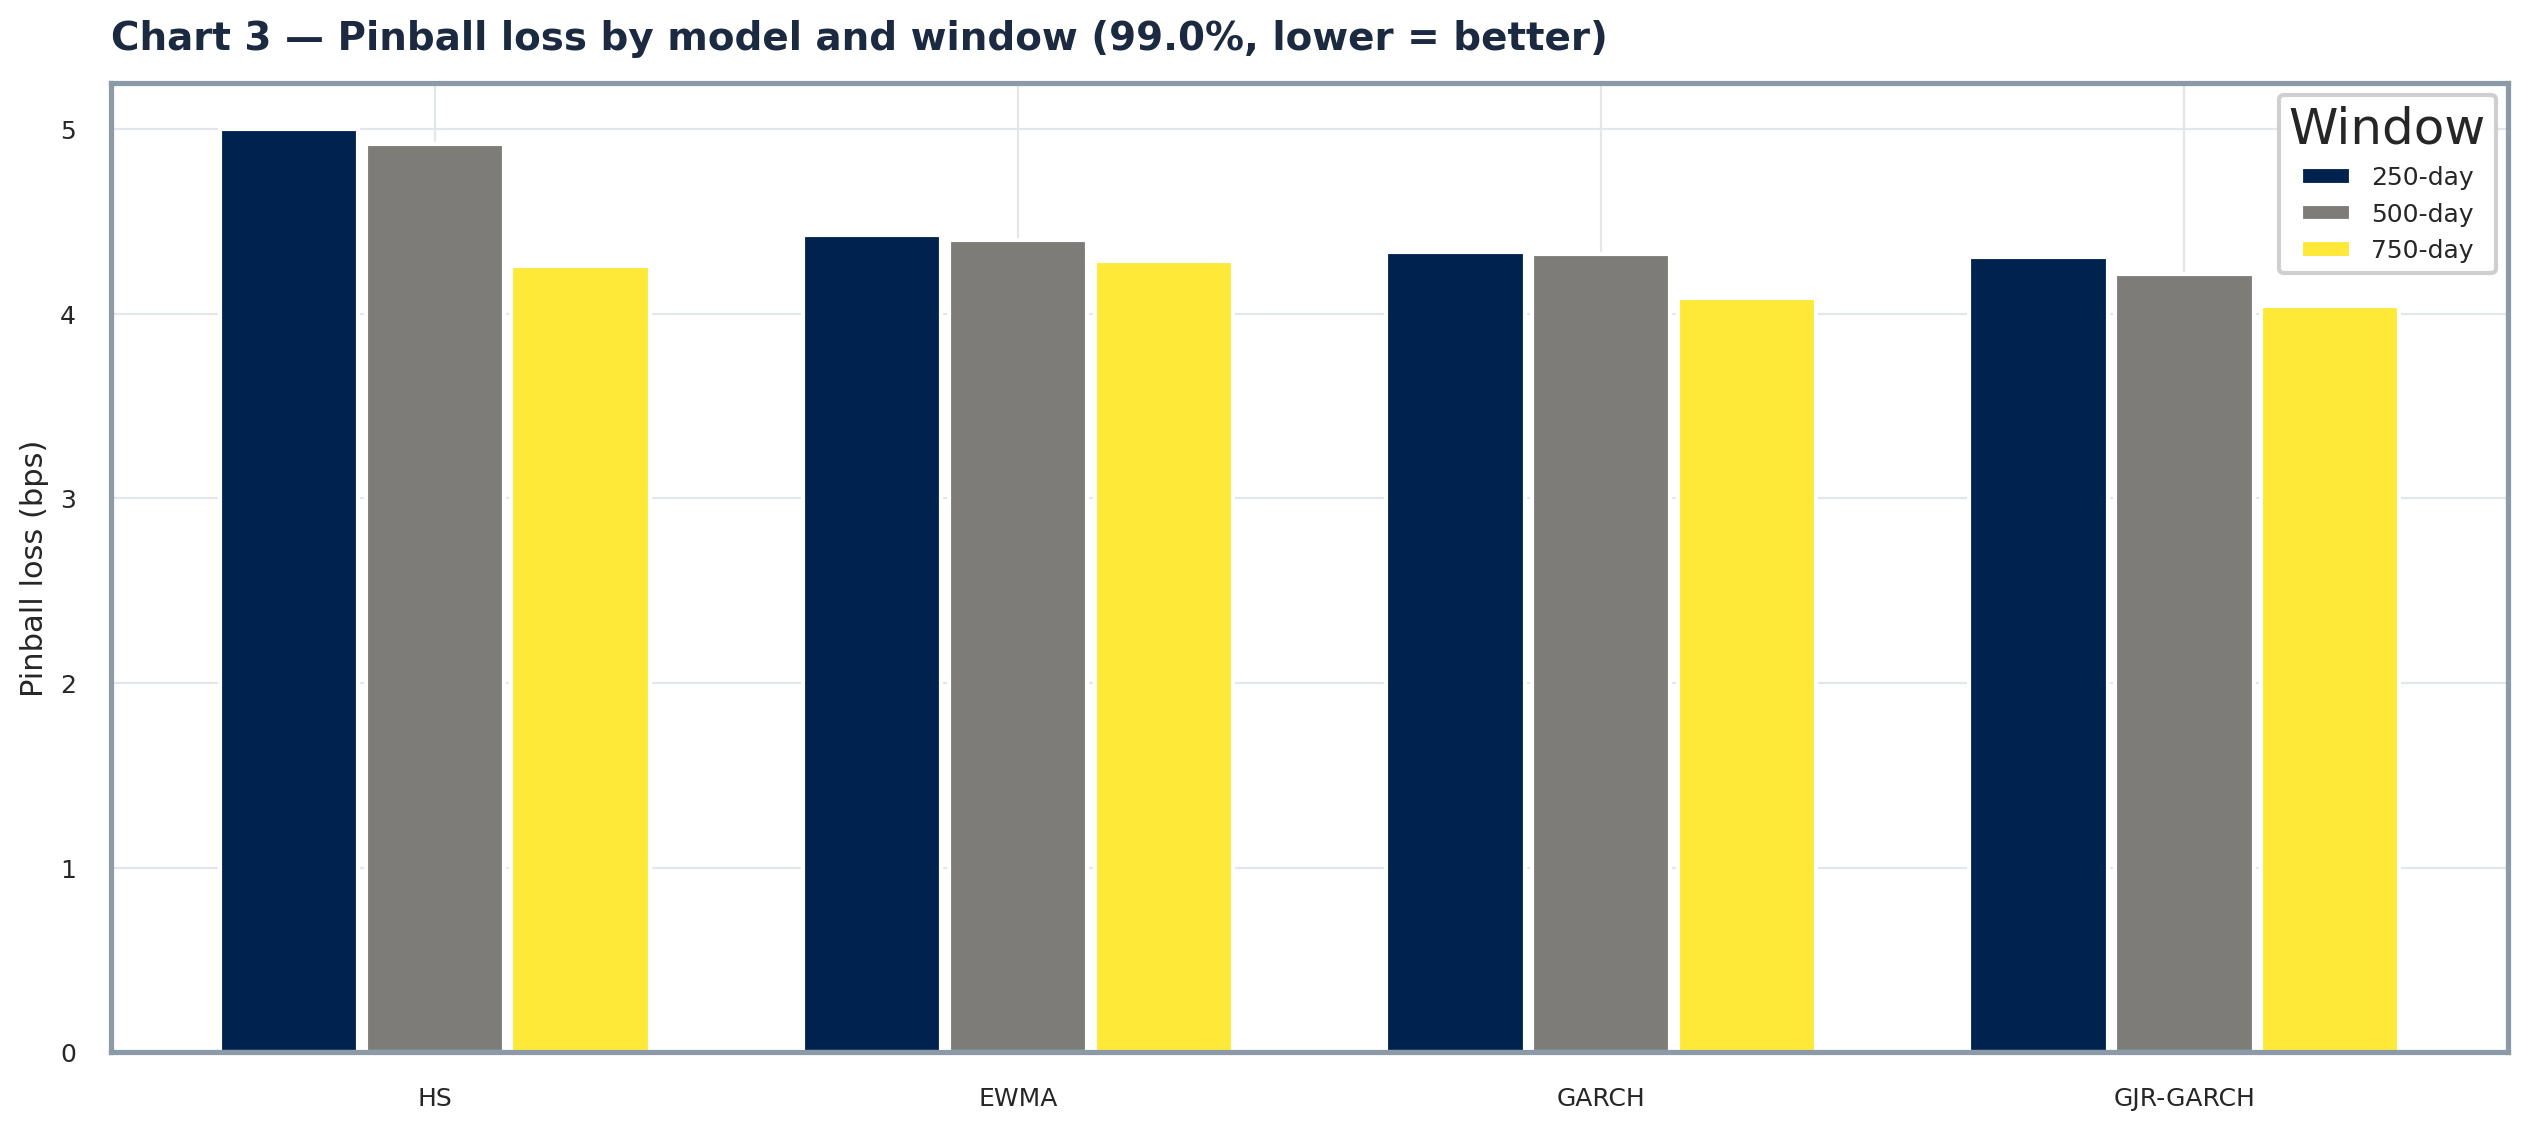

In [7]:
fig, ax = plt.subplots(figsize=(13, 6))
labels = [m[0] for m in MODELS]
xpos = np.arange(len(labels)); width = 0.25
for j, w in enumerate(WINDOWS):
    sub = comp[(comp.Window==w)&(comp.Confidence==HEADLINE_C)].set_index("Model").reindex(labels)
    ax.bar(xpos+(j-1)*width, sub["Pinball_bps"].values, width=width*0.95,
           label=f"{w}-day", color=plt.cm.cividis(j/2))
ax.set_xticks(xpos)
ax.set_xticklabels([l.replace("-scaled HS","").replace("Historical Simulation","HS") for l in labels])
ax.set_ylabel("Pinball loss (bps)"); ax.legend(title="Window")
ax.set_title(f"Chart 3 — Pinball loss by model and window ({HEADLINE_C:.1%}, lower = better)", loc="left")
fig.tight_layout(); fig.savefig(OUT/"charts/09_pinball_loss.png", facecolor="white"); plt.show()


## 5. Composite ranking

Each model is ranked 1 (best) to 4 (worst) on four headline criteria — CC p-value (↑), coverage error (↓), mean VaR %NAV (↓) and pinball loss (↓) — and the ranks are averaged. Equal weights; the lowest average rank is the recommended model. Calibration dominates by appearing in two of the four criteria.

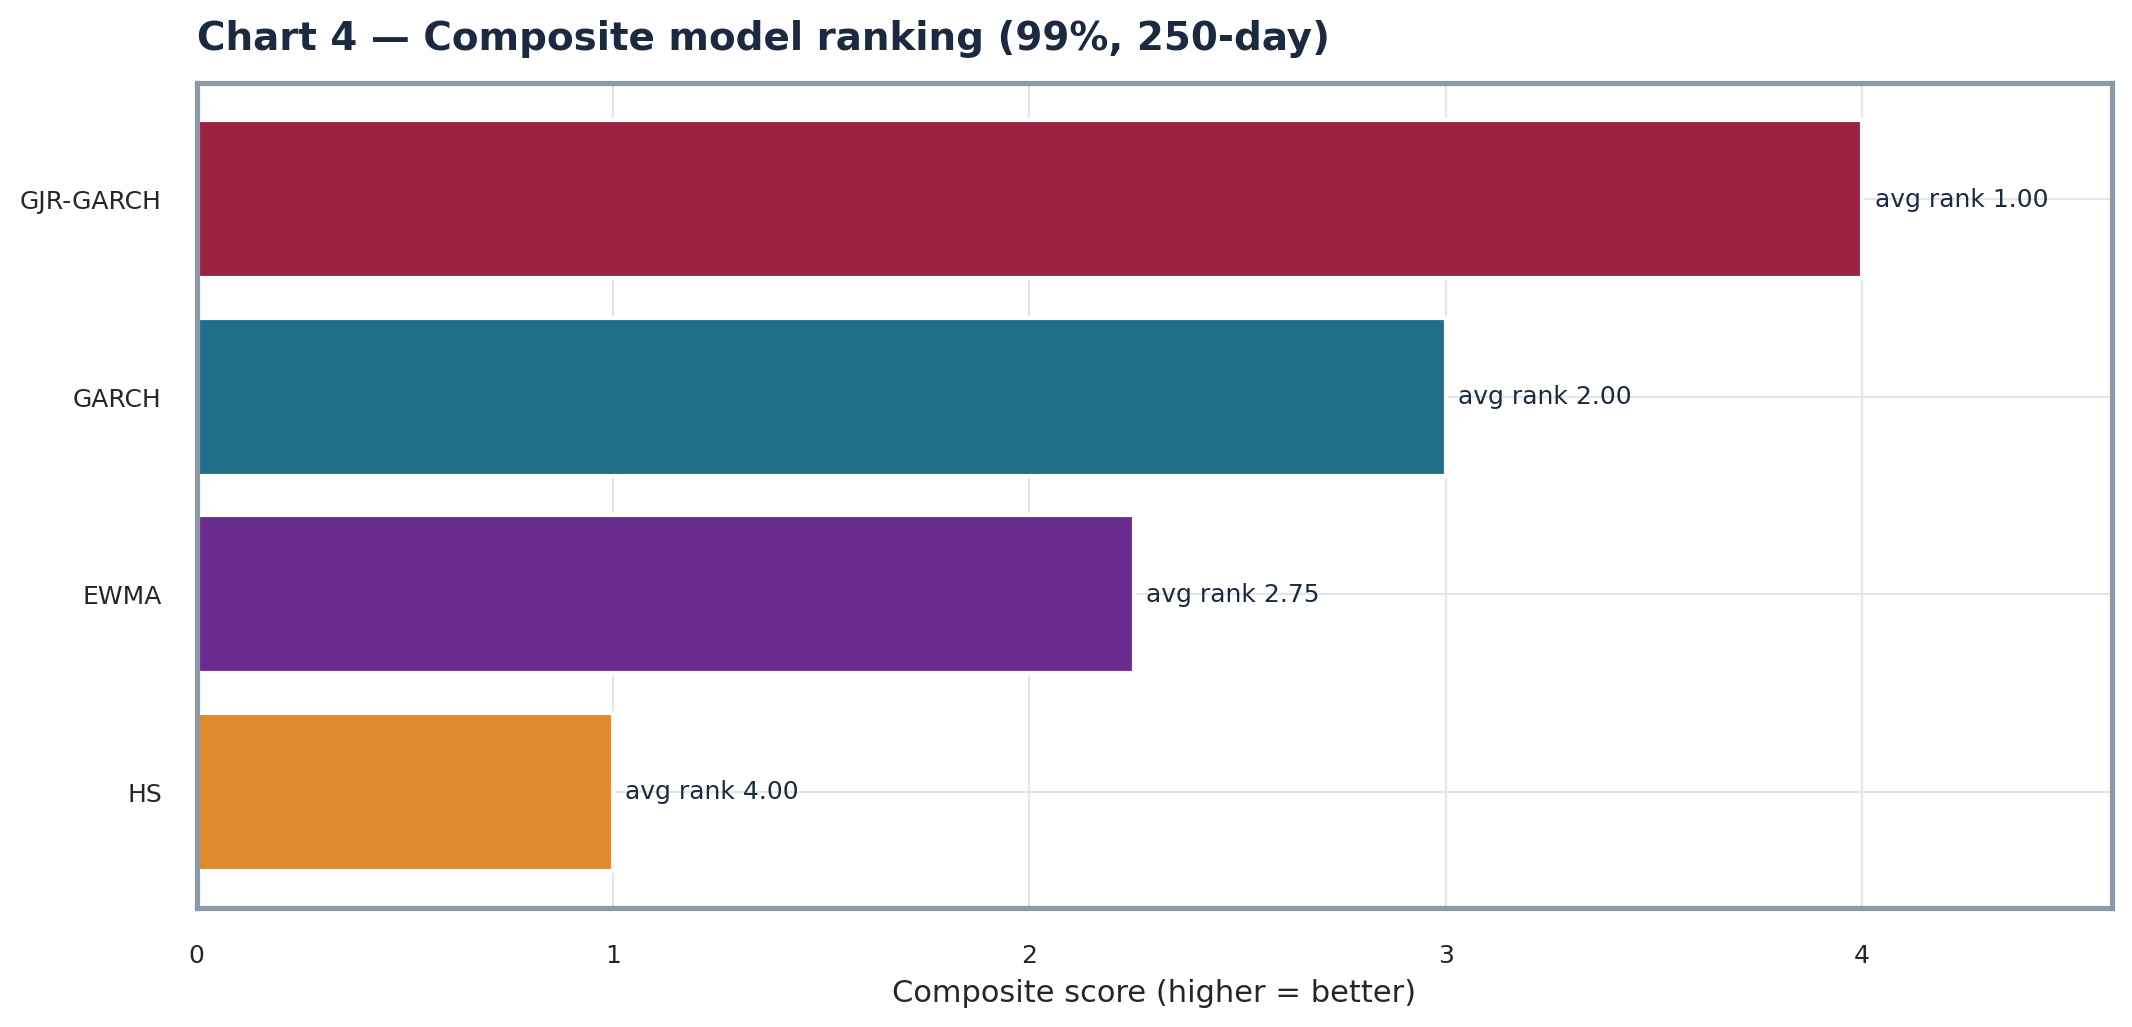

,CC_p,CovErr,MeanVaR_pctNAV,Pinball_bps,AvgRank
Model,,,,,
GJR-GARCH-scaled HS,1.00,1.00,1.00,1.00,1.00
GARCH-scaled HS,2.00,2.00,2.00,2.00,2.00
EWMA-scaled HS,3.00,2.00,3.00,3.00,2.75
Historical Simulation,4.00,4.00,4.00,4.00,4.00


In [8]:
crit = {"CC_p":False, "CovErr":True, "MeanVaR_pctNAV":True, "Pinball_bps":True}  # True = lower is better
ranks = pd.DataFrame(index=h.index)
for col, lower_better in crit.items():
    ranks[col] = h[col].rank(ascending=lower_better, method="min")
ranks["AvgRank"] = ranks.mean(axis=1)
ranks = ranks.sort_values("AvgRank")
best_model = ranks.index[0]

fig, ax = plt.subplots(figsize=(11, 5.5))
order = ranks.index[::-1]
colors = [PALETTE[dict(MODELS)[m]] for m in order]
ax.barh(range(len(order)), (5-ranks["AvgRank"].reindex(order)).values, color=colors, edgecolor="white")
ax.set_yticks(range(len(order)))
ax.set_yticklabels([m.replace("-scaled HS","").replace("Historical Simulation","HS") for m in order])
for i, m in enumerate(order):
    ax.text(5-ranks.loc[m,"AvgRank"]+0.03, i, f"avg rank {ranks.loc[m,'AvgRank']:.2f}",
            va="center", fontsize=9, color=PALETTE["ink"])
ax.set_xlabel("Composite score (higher = better)"); ax.set_xlim(0, 4.6)
ax.set_title("Chart 4 — Composite model ranking (99%, 250-day)", loc="left")
fig.tight_layout(); fig.savefig(OUT/"charts/09_composite_ranking.png", facecolor="white"); plt.show()
display(ranks.style.format("{:.2f}"))


## 6. Recommendation & executive summary

The cell below reads the ranking and writes the verdict: which model to deploy, why, and the trade-offs against the runners-up.

In [9]:
best_prefix = dict(MODELS)[best_model]
br = h.loc[best_model]; hs = h.loc["Historical Simulation"]
passers = h.index[h["CC_p"]>=0.05].tolist()

lines = [f"### Phase 9 verdict — recommended model: **{best_model}**\n",
    f"- **Ranking (99%, 250-day):** " +
      " › ".join(f"{m.replace('-scaled HS','').replace('Historical Simulation','HS')} ({ranks.loc[m,'AvgRank']:.2f})"
                 for m in ranks.index) + ".",
    f"- **Why {best_model.replace('-scaled HS','').replace('Historical Simulation','HS')}:** "
    f"conditional-coverage p={br['CC_p']:.3f} ({'passes' if br['CC_p']>=0.05 else 'fails'} the 5% gate), "
    f"breach rate {pct(br['Rate'])} vs {pct(1-HEADLINE_C)} target, Basel **{br['Basel']}**, "
    f"mean VaR {br['MeanVaR_pctNAV']:.2f}% of NAV, pinball loss {br['Pinball_bps']:.2f} bps.",
    f"- **vs unscaled HS:** HS posts CC p={hs['CC_p']:.3f} with mean VaR {hs['MeanVaR_pctNAV']:.2f}% of NAV "
    f"and pinball {hs['Pinball_bps']:.2f} bps — the volatility-scaled models {'improve' if br['Pinball_bps']<hs['Pinball_bps'] else 'match'} "
    f"calibration while adapting far faster to volatility clusters (Chart 2)."]
lines.append(f"- **Models passing conditional coverage at the headline:** "
             f"{', '.join(passers) if passers else 'none'}.")

# stability across all nine cells
pr = comp.groupby("Model")["CC_p"].apply(lambda s:(s>=0.05).mean()).reindex([m[0] for m in MODELS])
lines.append("\n**Robustness — share of 9 window×confidence cells passing conditional coverage:**")
for m,v in pr.items():
    lines.append(f"- {m}: {pct(v,0)}")
lines.append(f"\n> **Deploy {best_model}** as the production VaR model; retain unscaled HS as a slow-moving "
             f"challenger and the GARCH-family alternative for stressed-vol regimes. Phase 10 stress-tests the choice.")
display(Markdown("\n".join(lines)))


### Phase 9 verdict — recommended model: **GJR-GARCH-scaled HS**

- **Ranking (99%, 250-day):** GJR-GARCH (1.00) › GARCH (2.00) › EWMA (2.75) › HS (4.00).
- **Why GJR-GARCH:** conditional-coverage p=0.388 (passes the 5% gate), breach rate 1.35% vs 1.00% target, Basel **GREEN**, mean VaR 3.32% of NAV, pinball loss 4.31 bps.
- **vs unscaled HS:** HS posts CC p=0.037 with mean VaR 3.50% of NAV and pinball 5.00 bps — the volatility-scaled models improve calibration while adapting far faster to volatility clusters (Chart 2).
- **Models passing conditional coverage at the headline:** EWMA-scaled HS, GARCH-scaled HS, GJR-GARCH-scaled HS.

**Robustness — share of 9 window×confidence cells passing conditional coverage:**
- Historical Simulation: 56%
- EWMA-scaled HS: 89%
- GARCH-scaled HS: 100%
- GJR-GARCH-scaled HS: 100%

> **Deploy GJR-GARCH-scaled HS** as the production VaR model; retain unscaled HS as a slow-moving challenger and the GARCH-family alternative for stressed-vol regimes. Phase 10 stress-tests the choice.

## 7. Limitations

- **One realised history.** All rankings rest on a single 2020–2026 path dominated by a strong equity bull run. A crisis-heavy regime could reorder the models — the GARCH family typically widens its lead when volatility clusters hard.
- **Equal-weight composite.** The ranking weights its four criteria equally and lets calibration enter twice. A desk with a hard capital budget might up-weight efficiency; a regulator might demand calibration alone. The per-criterion ranks are shown so the weighting can be changed transparently.
- **Scoring in return space, frictionless P&L.** Pinball and Lopez use clean close-to-close returns with no fees, slippage or intraday path, so all models look better-behaved than a live book would.
- **Coverage inherited from Phase 8.** The CC/Kupiec p-values carry Phase 8's overlapping-window caveat; they are mildly optimistic but affect all models equally, so the *ranking* is robust even if the absolute p-values are not.